# Solver comparison

## Do the solvers find the best energy, and how does that change when the network gets bigger?

Gurobi is exact, so its energy is the reference. SA and QAOA are compared against it.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          
sys.path.append(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import load_all_solutions
from src.metrics import success_rate

sol = load_all_solutions()
sol["junctions"] = [p["n_junctions"] for p in sol["params"]]

networks = ["Net1", "Net2", "Net3"]
qubos = ["topological", "leak"]
solvers = ["gurobi", "sa", "qaoa"]      # qaoa is drawn once its solutions are saved
colors = {"gurobi": "black", "sa": "tab:blue", "qaoa": "tab:orange"}

# how many solutions we have
sol.groupby(["network", "solver"]).size().unstack(fill_value=0)

solver,gurobi,qaoa,sa
network,,,
Net1,10,10,10
Net2,10,0,10
Net3,10,0,10


## 1. How far is each solver from the best energy?

### - **gap**: solver energy minus Gurobi energy (0 means it found the optimum)
### - **success %**: share of the solver's runs that reached the optimum

In [2]:
best = sol[sol.solver == "gurobi"].set_index(["network", "formulation", "k"])["energy"]
sol["best"] = [best[(n, f, k)] for n, f, k in zip(sol.network, sol.formulation, sol.k)]
sol["gap"] = (sol["energy"] - sol["best"]).round(6)
sol["success %"] = [100 * success_rate(e, b) if e else np.nan for e, b in zip(sol.sample_energies, sol.best)]

others = sol[sol.solver != "gurobi"]
others.pivot_table(index=["formulation", "solver", "network"], columns="k", values="gap").round(2)

k                            1     2    3    4     5    6    8     10    15  \
formulation solver network                                                    
leak        qaoa   Net1     0.0  0.00  0.0  0.0  0.00  NaN  NaN   NaN   NaN   
            sa     Net1     0.0  0.00  0.0  0.0  0.00  NaN  NaN   NaN   NaN   
                   Net2     NaN  0.00  NaN  0.0   NaN  0.0  0.0  0.00   NaN   
                   Net3     NaN  0.03  NaN  NaN  0.13  NaN  NaN  0.05  0.22   
topological qaoa   Net1     0.0  0.00  0.0  0.0  0.00  NaN  NaN   NaN   NaN   
            sa     Net1     0.0  0.00  0.0  0.0  0.00  NaN  NaN   NaN   NaN   
                   Net2     NaN  0.00  NaN  0.0   NaN  0.0  0.0  0.61   NaN   
                   Net3     NaN  0.00  NaN  NaN  0.01  NaN  NaN  0.40  1.40   

k                             20  
formulation solver network        
leak        qaoa   Net1      NaN  
            sa     Net1      NaN  
                   Net2      NaN  
                   Net3     0.33  
topological qaoa   Net1      NaN  
            sa     Net1      NaN  
                   Net2      NaN  
                   Net3     1.65

## 2. Energy for each number of sensors

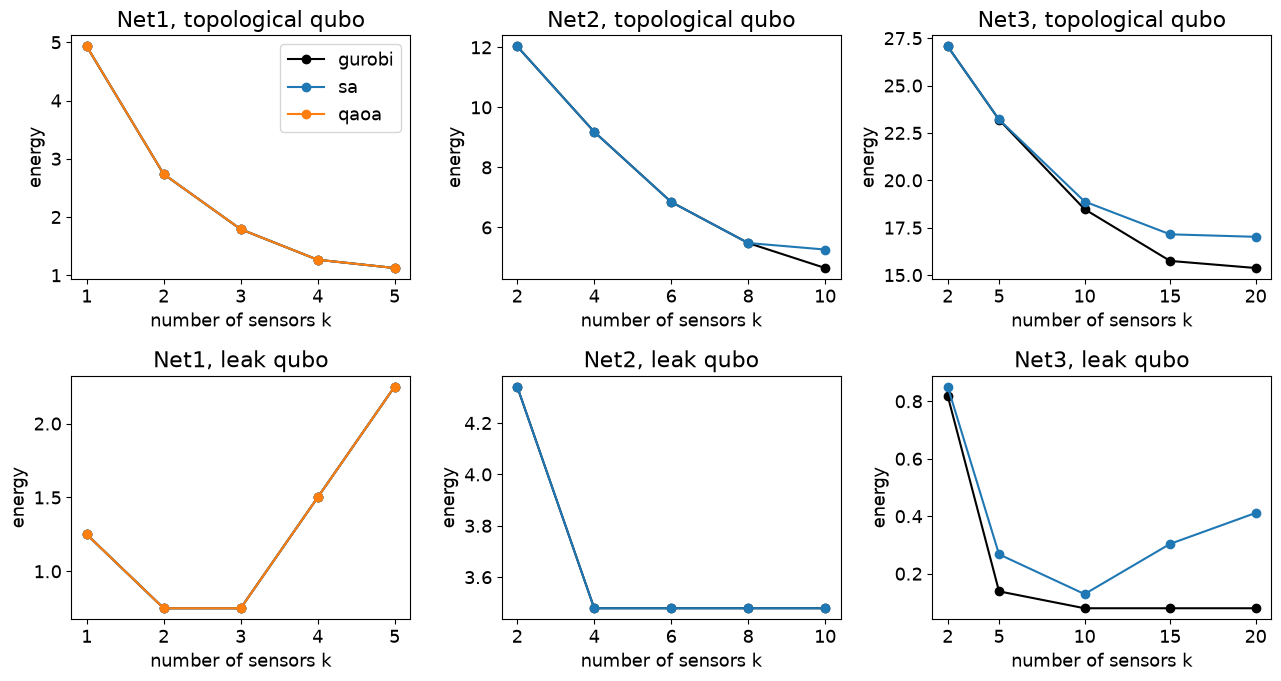

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for row, qubo in enumerate(qubos):
    for col, network in enumerate(networks):
        ax = axes[row, col]
        for solver in solvers:
            d = sol[(sol.formulation == qubo) & (sol.network == network) & (sol.solver == solver)].sort_values("k")
            if len(d):
                ax.plot(d["k"], d["energy"], marker="o", color=colors[solver], label=solver)
        ax.set_xticks(sorted(sol[sol.network == network]["k"].unique()))
        ax.set_title(f"{network}, {qubo} qubo")
        ax.set_xlabel("number of sensors k")
        ax.set_ylabel("energy")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("results/figures/energy_by_solver.png", dpi=200)

## 3. Repeat SA with 10 different seeds

One trial = one network, one QUBO, one k and one seed. In each trial SA does 100 runs and we keep its best valid placement.

In [4]:
from src.qubo import build_Q_topological, build_Q_leak, pick_penalty, energy
from src.solvers import solve_gurobi, solve_sa

builders = {"topological": build_Q_topological, "leak": build_Q_leak}
budgets = {"Net1": [1, 2, 3, 4, 5], "Net2": [2, 4, 6, 8, 10], "Net3": [2, 5, 10, 15, 20]}


def sa_gap(network, qubo, k, seed, num_sweeps=1000):
    """run sa once (100 runs inside) and return the gap of its best valid placement to gurobi."""
    build = builders[qubo]
    Q0, const0, _ = build(network, k, penalty=0)
    best = solve_gurobi(Q0, const0, k=k)[1]
    Q, const, _ = build(network, k, pick_penalty(Q0))
    samples = solve_sa(Q, const, num_sweeps=num_sweeps, seed=seed)[3]
    valid = [s for s in samples if sum(s) == k]
    return min(energy(Q0, const0, s) for s in valid) - best

In [5]:
rows = []
for network in networks:
    for qubo in qubos:
        for k in budgets[network]:
            for seed in range(10):
                rows.append({"network": network, "qubo": qubo, "k": k, "seed": seed,
                             "gap": sa_gap(network, qubo, k, seed)})
seeds = pd.DataFrame(rows)
seeds["found optimum"] = seeds["gap"] < 1e-6

Restricted license - for non-production use only - expires 2028-11-29


qubo,topological,leak
network,,
Net1,100.0,100.0
Net2,72.0,100.0
Net3,38.0,16.0


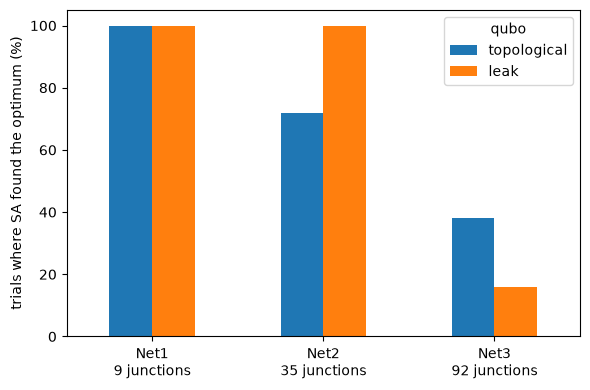

In [7]:
found = 100 * seeds.groupby(["network", "qubo"])["found optimum"].mean().unstack()[qubos]
display(found)

ax = found.plot.bar(figsize=(6, 4), rot=0, color=["tab:blue", "tab:orange"])
ax.set_xticklabels(["Net1\n9 junctions", "Net2\n35 junctions", "Net3\n92 junctions"])
ax.set_xlabel("")
ax.set_ylabel("trials where SA found the optimum (%)")
ax.legend(title="qubo")
plt.tight_layout()

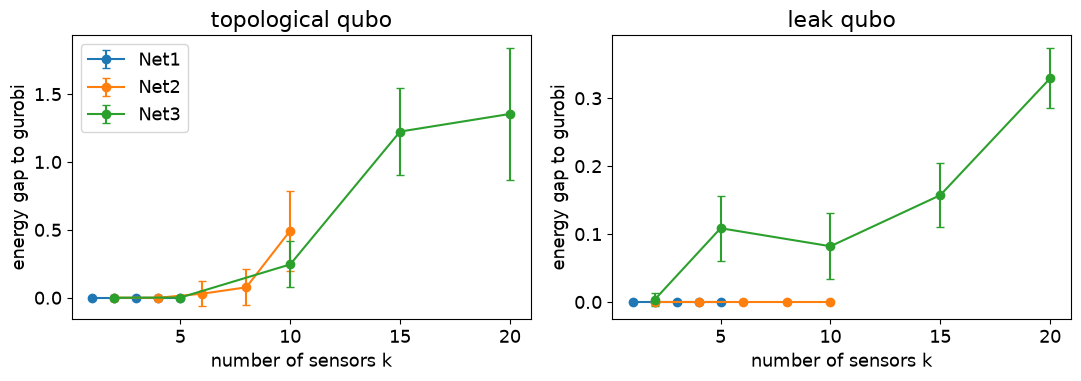

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, qubo in zip(axes, qubos):
    for network in networks:
        d = seeds[(seeds.qubo == qubo) & (seeds.network == network)].groupby("k")["gap"].agg(["mean", "std"])
        ax.errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, label=network)
    ax.set_title(f"{qubo} qubo")
    ax.set_xlabel("number of sensors k")
    ax.set_ylabel("energy gap to gurobi")
axes[0].legend()
plt.tight_layout()
plt.savefig("results/figures/sa_gap_by_k.png", dpi=200)

## 4. Does SA catch up if we give it more steps?

Net3 only, with 100, 1,000 (our default) and 10,000 steps per run, 5 seeds each.

In [9]:
rows = []
for qubo in qubos:
    for k in [10, 20]:
        for num_sweeps in [100, 1000, 10000]:
            for seed in range(5):
                rows.append({"qubo": qubo, "k": k, "steps": num_sweeps, "seed": seed,
                             "gap": sa_gap("Net3", qubo, k, seed, num_sweeps)})
effort = pd.DataFrame(rows)
effort.groupby(["qubo", "k", "steps"])["gap"].mean().unstack().round(2)

steps           100    1000   10000
qubo        k                      
leak        10   0.10   0.07   0.05
            20   0.46   0.32   0.21
topological 10   0.82   0.20   0.04
            20   2.60   1.44   0.91

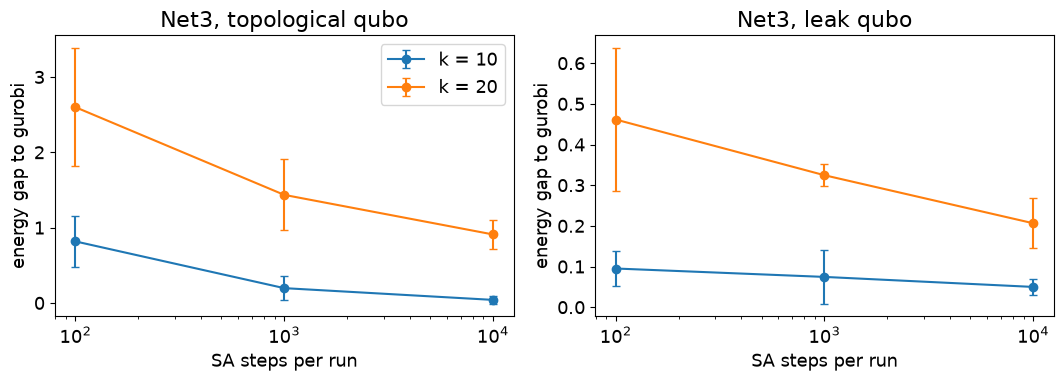

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, qubo in zip(axes, qubos):
    for k in [10, 20]:
        d = effort[(effort.qubo == qubo) & (effort.k == k)].groupby("steps")["gap"].agg(["mean", "std"])
        ax.errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=3, label=f"k = {k}")
    ax.set_xscale("log")
    ax.set_title(f"Net3, {qubo} qubo")
    ax.set_xlabel("SA steps per run")
    ax.set_ylabel("energy gap to gurobi")
axes[0].legend()
plt.tight_layout()
plt.savefig("results/figures/sa_more_steps.png", dpi=200)

In [11]:
size = pd.DataFrame({"variables": sol.groupby("network")["junctions"].first()})
size["pair terms"] = size["variables"] * (size["variables"] - 1) // 2
for solver in ["gurobi", "sa", "qaoa"]:
    size[f"{solver} time (s)"] = sol[sol.solver == solver].groupby("network")["runtime_s"].mean().round(3)
size

,variables,pair terms,gurobi time (s),sa time (s),qaoa time (s)
network,,,,,
Net1,9,36,0.009,0.015,42.378
Net2,35,595,0.026,0.097,NaN
Net3,92,4186,0.105,0.395,NaN


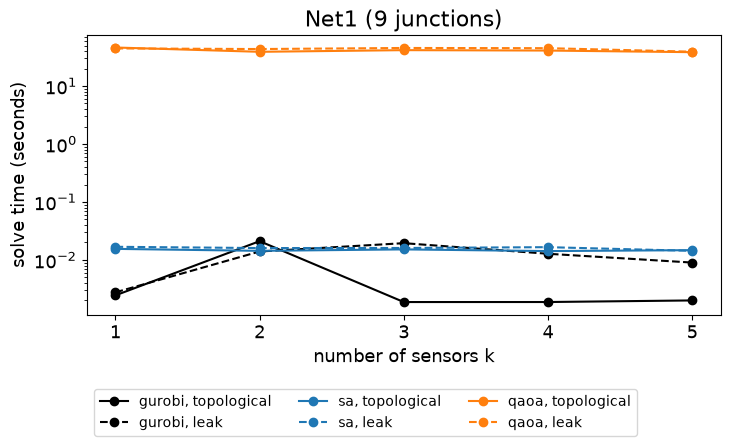

In [20]:
def plot_runtime(ax, network):
    """time of every solver for each number of sensors. solid = topological qubo, dashed = leak qubo."""
    runs = sol[sol.network == network]
    for solver in solvers:
        for qubo, style in zip(qubos, ["-", "--"]):
            d = runs[(runs.solver == solver) & (runs.formulation == qubo)].sort_values("k")
            if len(d):
                ax.plot(d["k"], d["runtime_s"], style, marker="o", color=colors[solver], label=f"{solver}, {qubo}")
    ax.set_yscale("log")
    ax.set_xticks(sorted(runs["k"].unique()))
    ax.set_xlabel("number of sensors k")
    ax.set_title(f"{network} ({runs['junctions'].iloc[0]} junctions)")


fig, ax = plt.subplots(figsize=(7.5, 4.5))
plot_runtime(ax, "Net1")
ax.set_ylabel("solve time (seconds)")
fig.legend(fontsize=10, ncol=3, loc="lower center")
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig("results/figures/runtime_Net1.png", dpi=200)

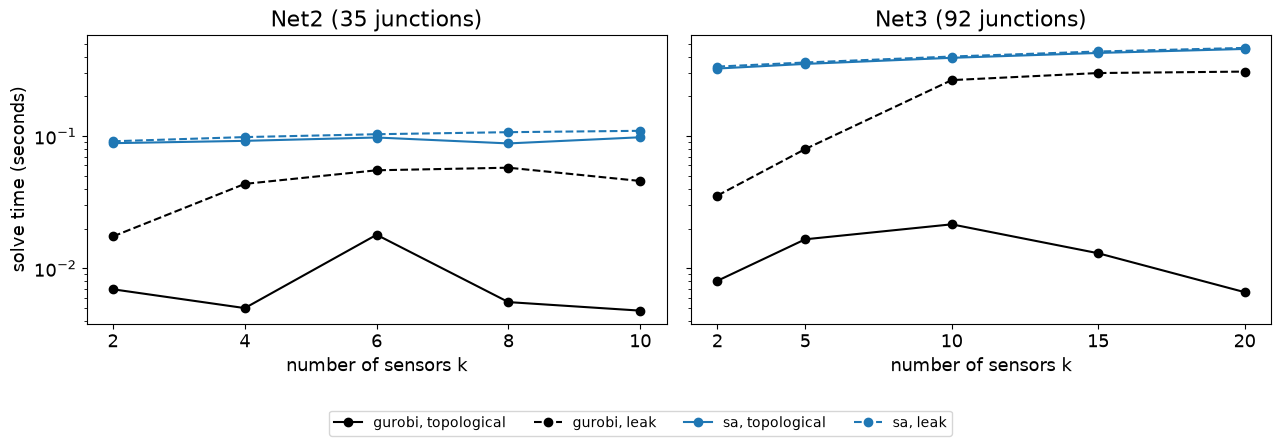

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, network in zip(axes, ["Net2", "Net3"]):
    plot_runtime(ax, network)
axes[0].set_ylabel("solve time (seconds)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=10, ncol=4, loc="lower center")
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.savefig("results/figures/runtime_Net2_Net3.png", dpi=200)

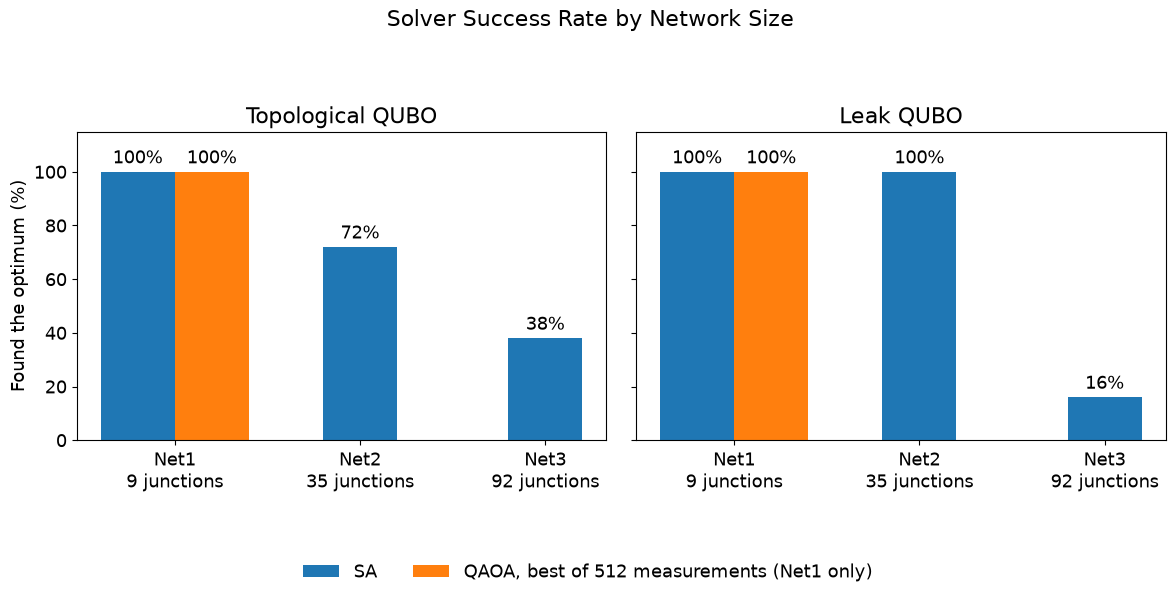

In [12]:
sa_found = 100 * seeds.groupby(["qubo", "network"])["found optimum"].mean()

qaoa = sol[sol.solver == "qaoa"]
qaoa_found = 100 * (qaoa["gap"] < 1e-6).groupby([qaoa.formulation, qaoa.network]).mean()

plt.rcParams.update({"font.size": 13})
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
x = np.arange(len(networks))

for ax, qubo in zip(axes, qubos):
    has_qaoa = np.array([(qubo, n) in qaoa_found for n in networks])

    bars = ax.bar(x - 0.2 * has_qaoa, [sa_found[(qubo, n)] for n in networks],
                  width=0.4, color="tab:blue", label="SA")
    ax.bar_label(bars, fmt="%.0f%%", padding=3)

    if has_qaoa.any():
        bars = ax.bar(x[has_qaoa] + 0.2, [qaoa_found[(qubo, n)] for n in networks if (qubo, n) in qaoa_found],
                      width=0.4, color="tab:orange", label="QAOA, best of 512 measurements (Net1 only)")
        ax.bar_label(bars, fmt="%.0f%%", padding=3)

    ax.set_xticks(x)
    ax.set_xticklabels(["Net1\n9 junctions", "Net2\n35 junctions", "Net3\n92 junctions"])
    ax.set_title(f"{qubo.capitalize()} QUBO")
    ax.set_ylim(0, 115)

axes[0].set_ylabel("Found the optimum (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Solver Success Rate by Network Size")
fig.tight_layout(rect=(0, 0.14, 1, 0.92))

os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/scalability.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. QAOA on Net1

QAOA measures its circuit 512 times, and Net1 has only 512 possible placements.
So "the best measurement is the optimum" can happen by chance.

A fairer question: what is the chance that **one try** finds the optimum?
- **SA**: one run
- **QAOA**: one measurement
- **random guess**: one placement picked at random

In [13]:
import itertools
from src.qubo import build_Q_topological, build_Q_leak, pick_penalty, energy

all_placements = list(itertools.product([0, 1], repeat=9))      # Net1 has 2^9 = 512 placements

rows = []
net1 = sol[sol.network == "Net1"]
for qubo in qubos:
    for k in sorted(net1.k.unique()):
        Q0, const0, _ = builders[qubo]("Net1", k, penalty=0)
        Q, const, _ = builders[qubo]("Net1", k, pick_penalty(Q0))
        optimum = best[("Net1", qubo, k)]

        # random guessing: how many of the 512 placements are optimal
        n_optimal = sum(abs(energy(Q, const, x) - optimum) < 1e-6 for x in all_placements)
        row = {"qubo": qubo, "k": k, "random guess": 100 * n_optimal / 512}
        for solver in ["sa", "qaoa"]:
            run = net1[(net1.formulation == qubo) & (net1.k == k) & (net1.solver == solver)].iloc[0]
            row[solver] = run["success %"]
        rows.append(row)

one_try = pd.DataFrame(rows).set_index(["qubo", "k"])[["sa", "qaoa", "random guess"]]
one_try.round(1)

sa  qaoa  random guess
qubo        k                          
topological 1  45.0   4.5           0.2
            2  46.0   1.6           0.2
            3  19.0   0.6           0.2
            4   8.0   0.4           0.2
            5   5.0   0.2           0.2
leak        1  26.0   3.9           0.2
            2  18.0   2.7           0.4
            3  22.0   2.0           0.4
            4  50.0   1.2           1.4
            5  82.0   0.8           0.6

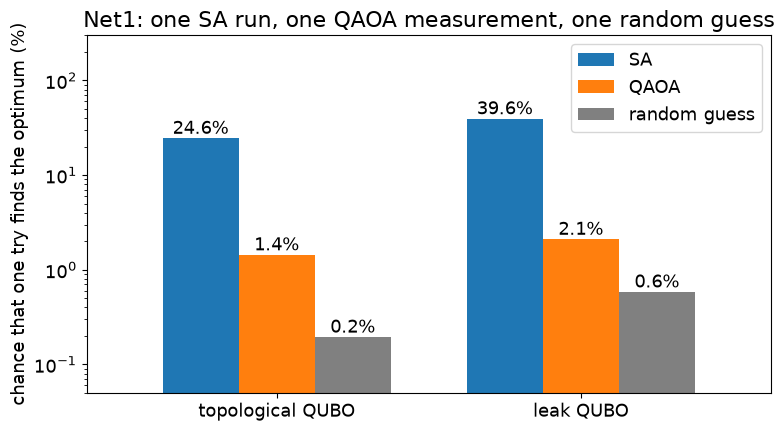

In [14]:
average = one_try.groupby("qubo").mean().loc[qubos]

ax = average.plot.bar(figsize=(8, 4.5), rot=0, color=["tab:blue", "tab:orange", "gray"], width=0.75)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%")
ax.set_yscale("log")
ax.set_ylim(0.05, 300)
ax.set_xticklabels([f"{q} QUBO" for q in qubos])
ax.set_xlabel("")
ax.set_ylabel("chance that one try finds the optimum (%)")
ax.set_title("Net1: one SA run, one QAOA measurement, one random guess")
ax.legend(["SA", "QAOA", "random guess"])
plt.tight_layout()
plt.savefig("results/figures/qaoa_one_try.png", dpi=200)

In [15]:
import glob, json

rows = []
for label, folder in [("before", "results/qaoa_before_rescaling"), ("after", "results/solutions")]:
    for path in sorted(glob.glob(f"{folder}/*_qaoa_*.json")):
        run = json.load(open(path))
        optimum = best[(run["network"], run["formulation"], run["k"])]
        energies = np.array(run["sample_energies"])
        sensors_used = np.array([len(s) for s in run["samples"]])
        rows.append({"rescaling": label, "qubo": run["formulation"], "k": run["k"],
                     "best is the optimum": abs(run["energy"] - optimum) < 1e-6,
                     "one try finds the optimum (%)": 100 * np.mean(np.abs(energies - optimum) < 1e-6),
                     "exactly k sensors (%)": 100 * np.mean(sensors_used == run["k"]),
                     "average energy": energies.mean()})

compare = pd.DataFrame(rows)
summary = compare.groupby(["qubo", "rescaling"]).mean(numeric_only=True).drop(columns="k")
summary["best is the optimum"] = compare.groupby(["qubo", "rescaling"])["best is the optimum"].sum().astype(str) + " of 5"
summary.loc[[(q, r) for q in qubos for r in ["before", "after"]]].round(1)

best is the optimum  one try finds the optimum (%)  \
qubo        rescaling                                                      
topological before                 2 of 5                            0.2   
            after                  5 of 5                            1.4   
leak        before                 5 of 5                            1.3   
            after                  5 of 5                            2.1   

                       exactly k sensors (%)  average energy  
qubo        rescaling                                         
topological before                      25.6            16.8  
            after                       37.5             7.0  
leak        before                      21.2            36.6  
            after                       40.9            13.7

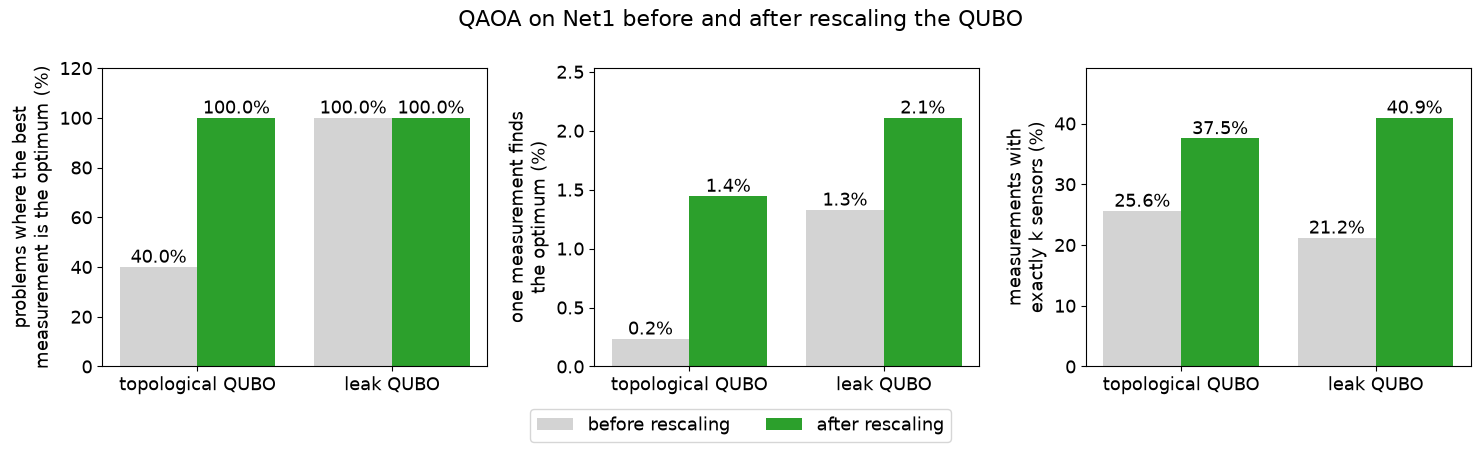

In [16]:
panels = {"problems where the best\nmeasurement is the optimum (%)": 100 * compare.groupby(["qubo", "rescaling"])["best is the optimum"].mean(),
          "one measurement finds\nthe optimum (%)": compare.groupby(["qubo", "rescaling"])["one try finds the optimum (%)"].mean(),
          "measurements with\nexactly k sensors (%)": compare.groupby(["qubo", "rescaling"])["exactly k sensors (%)"].mean()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
x = np.arange(len(qubos))
for ax, (title, values) in zip(axes, panels.items()):
    before = ax.bar(x - 0.2, [values[(q, "before")] for q in qubos], width=0.4, color="lightgray", label="before rescaling")
    after = ax.bar(x + 0.2, [values[(q, "after")] for q in qubos], width=0.4, color="tab:green", label="after rescaling")
    ax.bar_label(before, fmt="%.1f%%")
    ax.bar_label(after, fmt="%.1f%%")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{q} QUBO" for q in qubos])
    ax.set_ylabel(title)
    ax.set_ylim(0, 1.2 * values.max())

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.suptitle("QAOA on Net1 before and after rescaling the QUBO")
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.savefig("results/figures/qaoa_rescaling.png", dpi=200)

## Conclusion

- **Small networks:** SA always finds the Gurobi optimum on Net1 (9 junctions).
- **Larger networks:** SA becomes unreliable. On Net3 (92 junctions) it finds the optimum in 38% (topological) and 16% (leak) of trials.
- **Budget matters too:** on Net3 the gap grows with k, because the number of possible placements grows very fast.
- **More SA steps help but do not close the gap:** at k = 20, 100x more steps reduce the gap from 2.6 to 0.9.
- **Time is not the bottleneck for Gurobi and SA:** every run takes under a second. QAOA takes about 40 seconds per problem on the simulator.
- **QAOA (Net1 only):** after rescaling the QUBO, its best of 512 measurements is the optimum in all 10 problems. One measurement finds the optimum 1.4% (topological) and 2.1% (leak) of the time. That is better than a random guess (0.2% and 0.6%) but far below one SA run (25% and 40%).
- **Rescaling matters:** without it, QAOA found the optimum in only 7 of 10 problems and was close to random guessing.
- **QAOA cannot run on Net2 or Net3:** it needs one qubit per junction, and simulating 35 qubits needs about 550 GB of memory.